In [ ]:
import json
import matplotlib.pyplot as plt
from collections import Counter

print("1. Chargement des données...")

# Chargement des IDs de Chahinez
with open('knowledge_base_ids.json', 'r') as f:
    split_ids = json.load(f)
target_ids = set(split_ids)

# Chargement des annotations COCO
with open('instances_train2017.json', 'r') as f:
    instances_data = json.load(f)

print("2. Filtrage pour nos 10 000 images...")
# On garde uniquement les annotations qui concernent nos images
filtered_instances = [ann for ann in instances_data['annotations'] if ann['image_id'] in target_ids]
cat_id_to_name = {cat['id']: cat['name'] for cat in instances_data['categories']}

print("3. Calcul des 50 objets les plus fréquents...")
object_counts = Counter([cat_id_to_name[ann['category_id']] for ann in filtered_instances])
top_50 = object_counts.most_common(50)

# Afficher les 5 premiers dans le texte pour ton rapport
print("\nTop 5 des objets :")
for obj, count in top_50[:5]:
    print(f"- {obj} : {count} occurrences")

print("\n4. Création du graphique...")
labels, values = zip(*top_50)
plt.figure(figsize=(15, 6))
plt.bar(labels, values, color='skyblue')
plt.xticks(rotation=90)
plt.title('Top 50 Most Frequent Objects (Knowledge Base)')
plt.ylabel('Frequency')
plt.tight_layout()

# Sauvegarder l'image
plt.savefig('graph1_top50_objets.png')
print("Graphique sauvegardé ! Regarde en bas de la page.")
plt.show()

1. Chargement des données...


FileNotFoundError: [Errno 2] No such file or directory: 'instances_train2017.json'

Archive:  annotations_trainval2017.zip
  End-of-central-directory signature not found.  Either this file is not
  a zipfile, or it constitutes one disk of a multi-part archive.  In the
  latter case the central directory and zipfile comment will be found on
  the last disk(s) of this archive.
unzip:  cannot find zipfile directory in one of annotations_trainval2017.zip or
        annotations_trainval2017.zip.zip, and cannot find annotations_trainval2017.zip.ZIP, period.


1. Téléchargement direct du fichier COCO (ça peut prendre 1 minute)...
2. Extraction...
3. Chargement des données de Chahinez...
4. Chargement des annotations COCO...
5. Filtrage et calcul des objets...

Top 5 des objets :
- person : 21825 occurrences
- car : 3784 occurrences
- chair : 3163 occurrences
- book : 2034 occurrences
- bottle : 1847 occurrences

6. Création du graphique...
✅ C'est bon ! Le graphique est prêt.


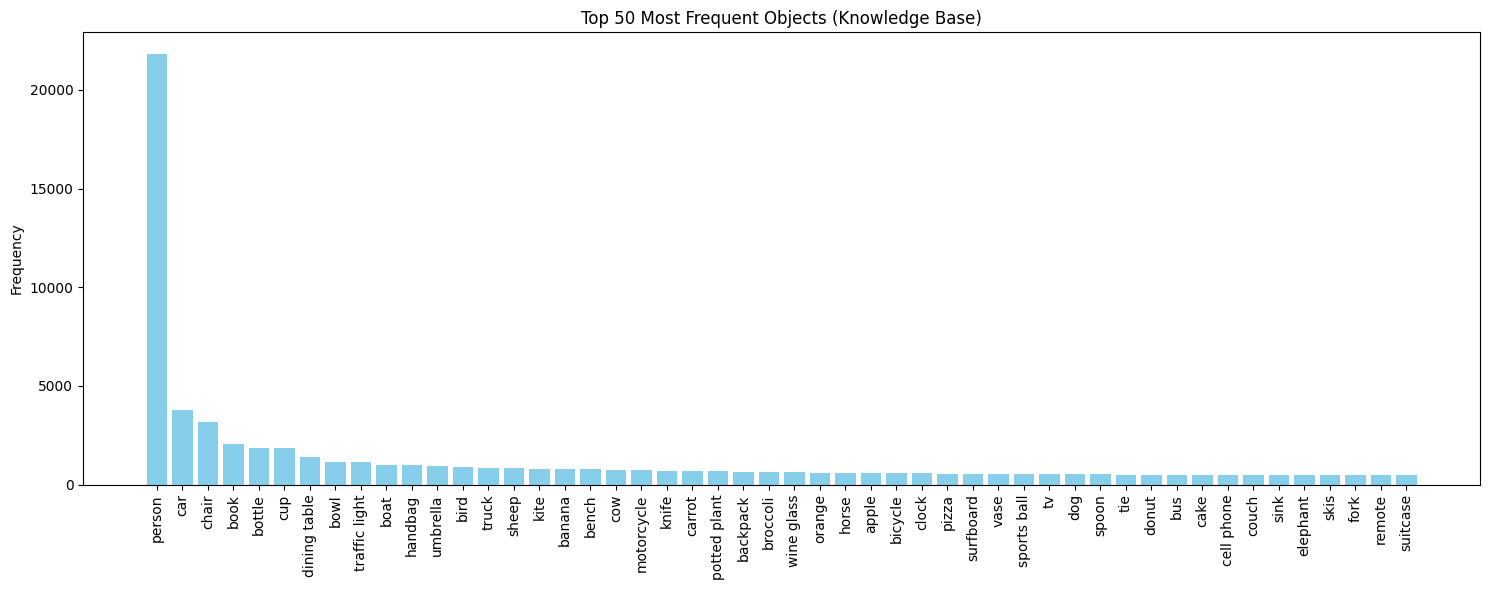

In [ ]:
import json
import urllib.request
import matplotlib.pyplot as plt
from collections import Counter

print("1. Téléchargement direct du fichier COCO (ça peut prendre 1 minute)...")
# On télécharge juste le fichier instances (environ 200 Mo)
url = "http://images.cocodataset.org/annotations/annotations_trainval2017.zip"
urllib.request.urlretrieve(url, "coco.zip")

print("2. Extraction...")
import zipfile
with zipfile.ZipFile("coco.zip", 'r') as zip_ref:
    zip_ref.extractall(".")

print("3. Chargement des données de Chahinez...")
# Chargement des IDs de Chahinez
with open('knowledge_base_ids.json', 'r') as f:
    split_ids = json.load(f)
target_ids = set(split_ids)

print("4. Chargement des annotations COCO...")
with open('annotations/instances_train2017.json', 'r') as f:
    instances_data = json.load(f)

print("5. Filtrage et calcul des objets...")
filtered_instances = [ann for ann in instances_data['annotations'] if ann['image_id'] in target_ids]
cat_id_to_name = {cat['id']: cat['name'] for cat in instances_data['categories']}

object_counts = Counter([cat_id_to_name[ann['category_id']] for ann in filtered_instances])
top_50 = object_counts.most_common(50)

print("\nTop 5 des objets :")
for obj, count in top_50[:5]:
    print(f"- {obj} : {count} occurrences")

print("\n6. Création du graphique...")
labels, values = zip(*top_50)
plt.figure(figsize=(15, 6))
plt.bar(labels, values, color='skyblue')
plt.xticks(rotation=90)
plt.title('Top 50 Most Frequent Objects (Knowledge Base)')
plt.ylabel('Frequency')
plt.tight_layout()

plt.savefig('graph1_top50_objets.png')
print("✅ C'est bon ! Le graphique est prêt.")
plt.show()

Calcul de la complexité de la scène...
Nombre moyen d'objets par image : 7.24
✅ Graphique 2 généré !


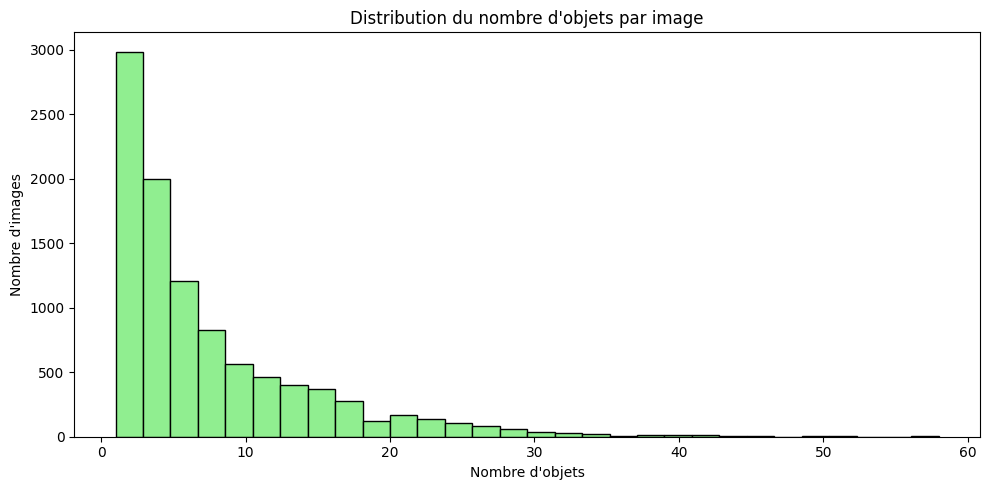

In [ ]:
print("Calcul de la complexité de la scène...")
# On compte combien d'objets il y a par image
objects_per_image = Counter([ann['image_id'] for ann in filtered_instances])
counts_per_image = list(objects_per_image.values())

# On calcule la moyenne
moyenne_objets = sum(counts_per_image) / len(counts_per_image)
print(f"Nombre moyen d'objets par image : {moyenne_objets:.2f}")

# Création du graphique
plt.figure(figsize=(10, 5))
plt.hist(counts_per_image, bins=30, color='lightgreen', edgecolor='black')
plt.title('Distribution du nombre d\'objets par image')
plt.xlabel('Nombre d\'objets')
plt.ylabel('Nombre d\'images')
plt.tight_layout()

# Sauvegarde
plt.savefig('graph2_complexite.png')
print("✅ Graphique 2 généré !")
plt.show()

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package averaged_perceptron_tagger to
[nltk_data]     /root/nltk_data...
[nltk_data]   Package averaged_perceptron_tagger is already up-to-
[nltk_data]       date!
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


1. Chargement des captions...
2. Analyse de la longueur des captions...
-> Longueur moyenne d'une caption : 10.46 mots
✅ Graphique 3 (Longueur) généré !


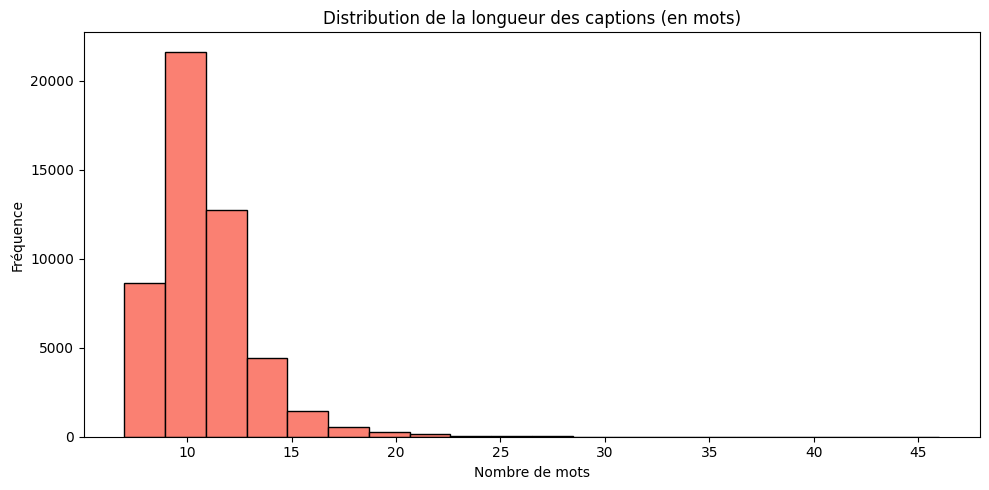


3. Analyse du vocabulaire et des classes grammaticales (POS)...
-> Taille du vocabulaire (estimée) : 3171 mots uniques
-> Top 5 des classes grammaticales (POS) :
   - NN : 15271 occurrences
   - DT : 10926 occurrences
   - IN : 8428 occurrences
   - JJ : 4705 occurrences
   - . : 3759 occurrences


In [ ]:
import nltk
from nltk import pos_tag
from nltk.tokenize import word_tokenize

# Téléchargement des ressources pour l'analyse du texte
nltk.download('punkt')
nltk.download('averaged_perceptron_tagger')
nltk.download('punkt_tab') # Parfois nécessaire pour les versions récentes

print("1. Chargement des captions...")
# On charge le fichier des captions qu'on a extrait tout à l'heure
with open('annotations/captions_train2017.json', 'r') as f:
    captions_data = json.load(f)

# On filtre pour n'avoir que nos 10 000 images
filtered_captions = [ann for ann in captions_data['annotations'] if ann['image_id'] in target_ids]
captions_list = [ann['caption'] for ann in filtered_captions]

print("2. Analyse de la longueur des captions...")
caption_lengths = [len(c.split()) for c in captions_list]
moyenne_mots = sum(caption_lengths) / len(caption_lengths)
print(f"-> Longueur moyenne d'une caption : {moyenne_mots:.2f} mots")

# Graphique de longueur
plt.figure(figsize=(10, 5))
plt.hist(caption_lengths, bins=20, color='salmon', edgecolor='black')
plt.title('Distribution de la longueur des captions (en mots)')
plt.xlabel('Nombre de mots')
plt.ylabel('Fréquence')
plt.tight_layout()
plt.savefig('graph3_longueur_captions.png')
print("✅ Graphique 3 (Longueur) généré !")
plt.show()

print("\n3. Analyse du vocabulaire et des classes grammaticales (POS)...")
# On prend un échantillon de 5000 captions pour que ça aille vite
sample_captions = captions_list[:5000]
all_words = []
for cap in sample_captions:
    all_words.extend(word_tokenize(cap.lower()))

vocab_size = len(set(all_words))
print(f"-> Taille du vocabulaire (estimée) : {vocab_size} mots uniques")

# Analyse POS (Noms, Verbes, Adjectifs...)
pos_tags = pos_tag(all_words)
pos_counts = Counter([tag for word, tag in pos_tags])

print("-> Top 5 des classes grammaticales (POS) :")
for tag, count in pos_counts.most_common(5):
    print(f"   - {tag} : {count} occurrences")

Analyse de la diversité (Intérieur vs Extérieur)...
-> Total objets d'intérieur : 4607
-> Total objets d'extérieur : 7633
✅ Graphique 4 (Diversité) généré !


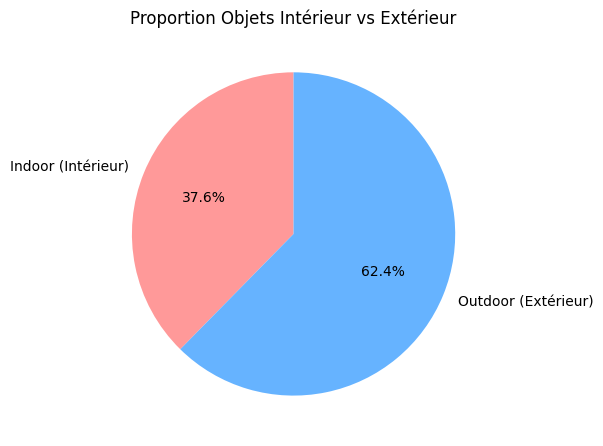

In [ ]:
print("Analyse de la diversité (Intérieur vs Extérieur)...")

# On définit une liste d'objets typiques d'intérieur et d'extérieur
indoor_objects = {'bed', 'couch', 'tv', 'laptop', 'dining table', 'toilet', 'microwave', 'oven', 'sink', 'refrigerator'}
outdoor_objects = {'car', 'tree', 'stop sign', 'traffic light', 'surfboard', 'skateboard', 'motorcycle', 'bus', 'train'}

# On additionne les occurrences de ces objets
indoor_count = sum(count for obj, count in object_counts.items() if obj in indoor_objects)
outdoor_count = sum(count for obj, count in object_counts.items() if obj in outdoor_objects)

print(f"-> Total objets d'intérieur : {indoor_count}")
print(f"-> Total objets d'extérieur : {outdoor_count}")

# Création du camembert (Pie chart)
plt.figure(figsize=(6, 6))
plt.pie([indoor_count, outdoor_count],
        labels=['Indoor (Intérieur)', 'Outdoor (Extérieur)'],
        autopct='%1.1f%%',
        colors=['#ff9999','#66b3ff'],
        startangle=90)
plt.title('Proportion Objets Intérieur vs Extérieur')
plt.tight_layout()

# Sauvegarde
plt.savefig('graph4_diversite.png')
print("✅ Graphique 4 (Diversité) généré !")
plt.show()

In [ ]:
import nltk
nltk.download('averaged_perceptron_tagger_eng')

[nltk_data] Downloading package averaged_perceptron_tagger_eng to
[nltk_data]     /root/nltk_data...
[nltk_data]   Package averaged_perceptron_tagger_eng is already up-to-
[nltk_data]       date!


True